### Task 1: Dataset Exploration and Understanding

In [30]:
import sys
from pathlib import Path
import pandas as pd

project_root = Path.cwd().resolve()
if not (project_root / "src").exists():
    project_root = project_root.parent

# Make src/data_pipeline.py importable whether the kernel starts in the project root or src/.
src_dir = str(project_root / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

dataset_root = Path(
    r"C:\TEMP\EXPERIMENTS\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)

# Number of images per class before the train/validation split; None uses all.
TRAIN_SAMPLE_SIZE = 100

train_dir = dataset_root / "train" / "train"
train_labels_path = dataset_root / "train_labels.csv"

# Test dataset folder.
test_dir = dataset_root / "test" / "test"

# Trained model weights are saved here.
models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)

# Kaggle prediction files are saved here.
submission_dir = project_root / "submission"
submission_dir.mkdir(exist_ok=True)

print(f"Dataset root: {dataset_root}")
print(f"Models folder: {models_dir}")
print(f"Submission folder: {submission_dir}")
print(
    f"Folders in dataset root: {[p.name for p in dataset_root.iterdir() if p.is_dir()]}"
)
print(f"Train folder: {train_dir}")
print(f"Test folder: {test_dir}")

Dataset root: C:\TEMP\EXPERIMENTS\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch
Models folder: C:\TEMP\EXPERIMENTS\kaggle-competition\models
Submission folder: C:\TEMP\EXPERIMENTS\kaggle-competition\submission
Folders in dataset root: ['test', 'train']
Train folder: C:\TEMP\EXPERIMENTS\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train
Test folder: C:\TEMP\EXPERIMENTS\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\test


In [31]:
# Load and take an equal, stratified sample from each class.
def training_image_path(image_id):
    return train_dir / f"{int(image_id):05d}.jpg"


def training_image_paths_for(labels):
    return [training_image_path(image_id) for image_id in labels["image_id"]]


source_image_labels = pd.read_csv(train_labels_path)

if TRAIN_SAMPLE_SIZE is not None:
    if TRAIN_SAMPLE_SIZE < 1:
        raise ValueError("TRAIN_SAMPLE_SIZE must be at least 1")
    class_counts = source_image_labels["class"].value_counts()
    max_sample_per_class = class_counts.min()
    if TRAIN_SAMPLE_SIZE > max_sample_per_class:
        raise ValueError(
            f"TRAIN_SAMPLE_SIZE cannot exceed {max_sample_per_class}, "
            "the number of labels in the smallest class"
        )
    source_image_labels = (
        source_image_labels.groupby("class", group_keys=False)
        .sample(n=TRAIN_SAMPLE_SIZE, random_state=42)
        .reset_index(drop=True)
    )

source_image_labels_count = len(source_image_labels)

print(f"Shape: {source_image_labels.shape}")
print(f"Columns and dtypes:\n{source_image_labels.dtypes.to_string()}")
print(f"\nMissing values:\n{source_image_labels.isna().sum().to_string()}")
print(f"\nDuplicate image_ids: {source_image_labels['image_id'].duplicated().sum()}")

missing_training_files = [
    path for path in training_image_paths_for(source_image_labels) if not path.is_file()
]
print(
    f"Selected labels without an image file: {[path.name for path in missing_training_files]}"
)

print(
    f"\nUnique classes ({source_image_labels['class'].nunique()}): {sorted(source_image_labels['class'].unique())}"
)
print("\nFirst rows:")
print(source_image_labels.head().to_string(index=False))

Shape: (63660, 2)
Columns and dtypes:
image_id    int64
class         str

Missing values:
image_id    0
class       0

Duplicate image_ids: 0
Selected labels without an image file: []

Unique classes (8): ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

First rows:
 image_id    class
        1   DogEye
        2 DogMouth
        3  DogFace
        4  DogNose
        5  DogNose


In [32]:
# Inspect the unlabeled test images.
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

test_files = sorted(test_dir.glob("*.jpg"))
print(f"Test images: {len(test_files)}")
print(f"First files: {[p.name for p in test_files[:5]]}")
print(f"File types in folder: {Counter(p.suffix for p in test_dir.iterdir())}")


def get_size_mode(path):
    with Image.open(path) as img:
        return img.size, img.mode


sizes, modes = Counter(), Counter()
# Image.open() releases the GIL during disk I/O, so threads overlap file reads.
with ThreadPoolExecutor(max_workers=8) as executor:
    for size, mode in executor.map(get_size_mode, test_files):
        sizes[size] += 1
        modes[mode] += 1
print(f"Test image sizes: {sizes.most_common(5)}")
print(f"Test image modes: {dict(modes)}")

Test images: 29443
First files: ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
File types in folder: Counter({'.jpg': 29443})
Test image sizes: [((40, 40), 503), ((50, 50), 402), ((80, 80), 370), ((30, 30), 349), ((60, 60), 343)]
Test image modes: {'RGB': 29443}


In [33]:
# Report the number of images in each class.
import pandas as pd

if train_dir.exists():
    image_files = sorted(
        path for path in training_image_paths_for(source_image_labels) if path.is_file()
    )
    print(f"  Image count: {len(image_files)}")
    print(f"  Sample files: {[path.name for path in image_files[:5]]}")
    print(f"  File extensions: {sorted({path.suffix.lower() for path in image_files})}")
else:
    raise FileNotFoundError(f"Training image directory not found: {train_dir}")

print(f"\nTraining labels shape: {source_image_labels.shape}")
print(f"Training label columns: {source_image_labels.columns.tolist()}")
print("Training examples per class:")
print(source_image_labels["class"].value_counts().sort_index().to_string())
print("\nTraining label samples:")
print(source_image_labels.head().to_string(index=False))

  Image count: 63660
  Sample files: ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
  File extensions: ['.jpg']

Training labels shape: (63660, 2)
Training label columns: ['image_id', 'class']
Training examples per class:
class
CatEye      13884
CatFace      6942
CatMouth     6942
CatNose      6942
DogEye      11580
DogFace      5790
DogMouth     5790
DogNose      5790

Training label samples:
 image_id    class
        1   DogEye
        2 DogMouth
        3  DogFace
        4  DogNose
        5  DogNose


In [34]:
# Report class imbalance in the training labels.
class_counts = source_image_labels["class"].value_counts().sort_index()
class_percentages = (class_counts / class_counts.sum() * 100).round(2)
imbalance_ratio = class_counts.max() / class_counts.min()

print(f"Classes: {len(class_counts)}")
print(f"Largest class: {class_counts.idxmax()} ({class_counts.max()} images)")
print(f"Smallest class: {class_counts.idxmin()} ({class_counts.min()} images)")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.2f}")
print(pd.DataFrame({"count": class_counts, "percent": class_percentages}).to_string())

if imbalance_ratio == 1:
    print("\nClasses are perfectly balanced.")
else:
    print("\nClasses are imbalanced; consider class weights or resampling.")

Classes: 8
Largest class: CatEye (13884 images)
Smallest class: DogFace (5790 images)
Imbalance ratio (largest / smallest): 2.40
          count  percent
class                   
CatEye    13884    21.81
CatFace    6942    10.90
CatMouth   6942    10.90
CatNose    6942    10.90
DogEye    11580    18.19
DogFace    5790     9.10
DogMouth   5790     9.10
DogNose    5790     9.10

Classes are imbalanced; consider class weights or resampling.


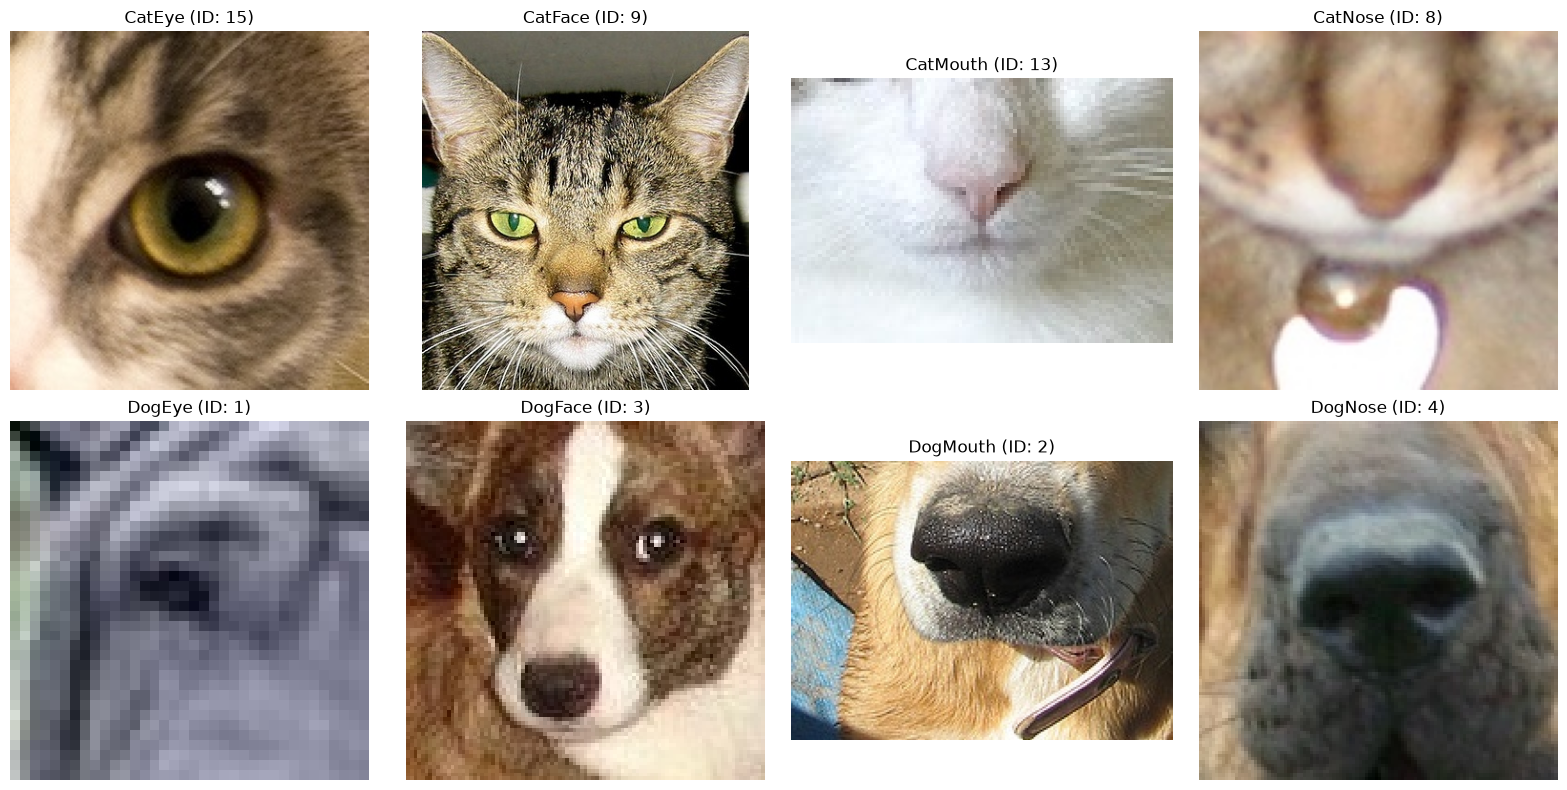

In [35]:
# Display one representative training image for each class.
from math import ceil
from PIL import Image
import matplotlib.pyplot as plt

representatives = source_image_labels.groupby("class", sort=True).first().reset_index()
num_images = len(representatives)
num_columns = min(4, num_images)
num_rows = ceil(num_images / num_columns)

fig, axes = plt.subplots(num_rows, num_columns, figsize=(4 * num_columns, 4 * num_rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (_, sample) in zip(axes, representatives.iterrows()):
    image_path = training_image_path(sample["image_id"])
    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image for class {sample['class']} not found: {image_path}"
        )

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{sample['class']} (ID: {int(sample['image_id'])})")
    ax.axis("off")

for ax in axes[num_images:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
# Find training images whose dimensions differ from the most common size.
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from PIL import Image


def get_dimensions(image_path):
    with Image.open(image_path) as image:
        return image_path, image.size


existing_paths = sorted(
    path for path in training_image_paths_for(source_image_labels) if path.is_file()
)
# Image.open() releases the GIL during disk I/O, so threads overlap file reads.
with ThreadPoolExecutor(max_workers=8) as executor:
    image_dimensions = dict(executor.map(get_dimensions, existing_paths))

if not image_dimensions:
    raise ValueError(f"No images found in {train_dir}")

dimension_counts = Counter(image_dimensions.values())
common_size, common_count = dimension_counts.most_common(1)[0]
print(f"Checked {len(image_dimensions)} images.")
print(f"Most common size: {common_size[0]}x{common_size[1]} ({common_count} images)")

# Largest and smallest images by pixel area (width x height).
largest_path, largest_size = max(
    image_dimensions.items(), key=lambda item: item[1][0] * item[1][1]
)
smallest_path, smallest_size = min(
    image_dimensions.items(), key=lambda item: item[1][0] * item[1][1]
)
print(f"Largest dimension: {largest_size[0]}x{largest_size[1]} ({largest_path.name})")
print(
    f"Smallest dimension: {smallest_size[0]}x{smallest_size[1]} ({smallest_path.name})"
)

rare_dimension_images = sum(count for count in dimension_counts.values() if count < 10)

print(
    f"Images with a dimension that occurs fewer than 10 times: {rare_dimension_images}"
)

inconsistent_images = {
    image_path: dimensions
    for image_path, dimensions in image_dimensions.items()
    if dimensions != common_size
}
if inconsistent_images:
    print(
        f"Found {len(inconsistent_images)} images differing from the most common size ({common_size[0]}x{common_size[1]})"
    )
else:
    print(f"All images have the same size: {common_size[0]}x{common_size[1]}.")

Checked 63660 images.
Most common size: 40x40 (1062 images)
Largest dimension: 2219x2219 (08326.jpg)
Smallest dimension: 4x4 (14181.jpg)
Images with a dimension that occurs fewer than 10 times: 9501
Found 62598 images differing from the most common size (40x40)


Checked 63660 images using a blur threshold of 50.0.
Potentially blurry images: 17376
10 blurriest images (lowest Laplacian variance first):
  14669.jpg: sharpness score = 0.34
  12118.jpg: sharpness score = 0.55
  44794.jpg: sharpness score = 0.70
  34351.jpg: sharpness score = 0.74
  37907.jpg: sharpness score = 0.86
  34014.jpg: sharpness score = 0.94
  38359.jpg: sharpness score = 0.97
  32164.jpg: sharpness score = 0.99
  62253.jpg: sharpness score = 1.02
  06333.jpg: sharpness score = 1.10


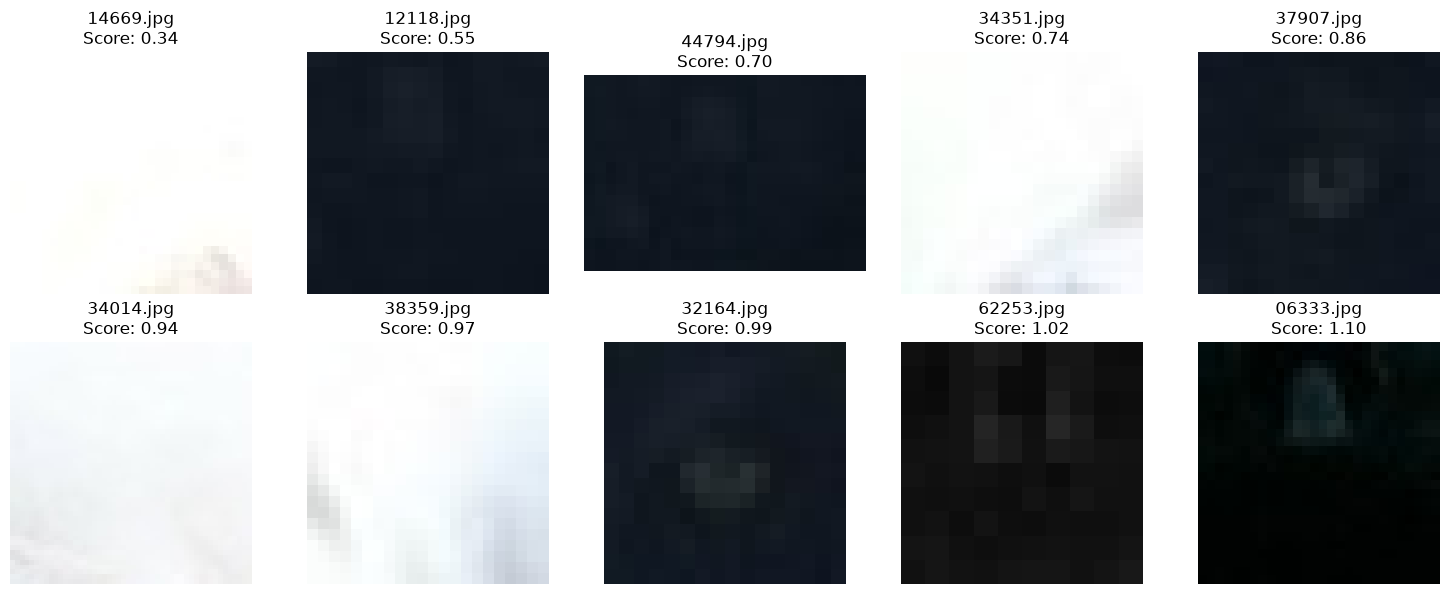

In [37]:
# Find potentially blurry training images using Laplacian variance.
import numpy as np
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
import matplotlib.pyplot as plt
from scipy.ndimage import laplace

# Lower scores indicate less visible detail; tune this threshold for the dataset.
blur_threshold = 50.0


def compute_blur_score(image_path):
    with Image.open(image_path) as image:
        grayscale = image.convert("L").resize((128, 128))
        pixels = np.asarray(grayscale, dtype=np.float32)
    return image_path, float(laplace(pixels).var())


existing_paths = [
    path
    for path in sorted(training_image_paths_for(source_image_labels))
    if path.is_file()
]
# Image.open() releases the GIL during disk I/O, so threads overlap file reads.
with ThreadPoolExecutor(max_workers=8) as executor:
    blur_scores = dict(executor.map(compute_blur_score, existing_paths))

if not blur_scores:
    raise ValueError(f"No images found in {train_dir}")

blurry_images = {
    image_path: score
    for image_path, score in blur_scores.items()
    if score < blur_threshold
}
print(
    f"Checked {len(blur_scores)} images using a blur threshold of {blur_threshold:.1f}."
)
if blurry_images:
    print(f"Potentially blurry images: {len(blurry_images)}")
    blurriest_images = sorted(blurry_images.items(), key=lambda item: item[1])[:10]
    print("10 blurriest images (lowest Laplacian variance first):")
    for image_path, score in blurriest_images:
        print(f"  {image_path.name}: sharpness score = {score:.2f}")

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for ax, (image_path, score) in zip(axes.flat, blurriest_images):
        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"{image_path.name}\nScore: {score:.2f}")
        ax.axis("off")
    for ax in axes.flat[len(blurriest_images) :]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()
else:
    print("No images fell below the blur threshold.")

In [38]:
# Find corrupted or unreadable image files in the training folder.
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, UnidentifiedImageError

checked_files = [
    path
    for path in sorted(training_image_paths_for(source_image_labels))
    if path.is_file()
]


def check_corrupted(image_path):
    try:
        with Image.open(image_path) as image:
            image.verify()
        # verify() does not catch every problem, so fully decode the image as well.
        with Image.open(image_path) as image:
            image.load()
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as error:
        return image_path, f"{type(error).__name__}: {error}"
    return image_path, None


# Image.open() releases the GIL during disk I/O, so threads overlap file reads.
with ThreadPoolExecutor(max_workers=8) as executor:
    corrupted_files = {
        path: reason
        for path, reason in executor.map(check_corrupted, checked_files)
        if reason is not None
    }

print(f"Checked {len(checked_files)} files.")
if corrupted_files:
    print(f"Found {len(corrupted_files)} corrupted files:")
    for image_path, reason in corrupted_files.items():
        print(f"  {image_path.name}: {reason}")
else:
    print("No corrupted files found.")

# Remove corrupted images from the labels table only; the image files are left on disk.
corrupted_ids = {int(path.stem) for path in corrupted_files if path.stem.isdigit()}
if corrupted_ids:
    before = len(source_image_labels)
    source_image_labels = source_image_labels[
        ~source_image_labels["image_id"].isin(corrupted_ids)
    ].reset_index(drop=True)
    print(
        f"Removed {before - len(source_image_labels)} corrupted rows from source_image_labels ({len(source_image_labels)} remain)."
    )

Checked 63660 files.
No corrupted files found.


In [39]:
# Check for exact duplicate images, both within train and between train and test.
# Exact copies are byte-identical files, so they share a file hash.
import hashlib
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor


def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


train_files = training_image_paths_for(source_image_labels)
test_files = sorted(test_dir.glob("*.jpg"))

# Reading file bytes releases the GIL, so threads overlap disk I/O.
with ThreadPoolExecutor(max_workers=8) as executor:
    train_hashes = executor.map(file_hash, train_files)
    train_by_hash = defaultdict(list)
    for path, digest in zip(train_files, train_hashes):
        train_by_hash[digest].append(path)

    test_hashes = executor.map(file_hash, test_files)
    test_by_hash = defaultdict(list)
    for path, digest in zip(test_files, test_hashes):
        test_by_hash[digest].append(path)

# 1. Exact duplicates within train: groups of two or more identical files.
within_train = [paths for paths in train_by_hash.values() if len(paths) > 1]
print(f"Exact duplicate groups within train: {len(within_train)}")
for paths in within_train:
    print("  " + " == ".join(f"train/{path.name}" for path in paths))

# 2. Exact duplicates between train and test.
train_vs_test = [
    (train_path, test_path)
    for digest, train_paths in train_by_hash.items()
    if digest in test_by_hash
    for train_path in train_paths
    for test_path in test_by_hash[digest]
]
print(f"Exact duplicates between train and test: {len(train_vs_test)}")
for train_path, test_path in train_vs_test:
    print(f"  train/{train_path.name} == test/{test_path.name}")

if not (within_train or train_vs_test):
    print("\nNo exact duplicate images found, so there is no duplicate-based leakage.")

# 3. Remove duplicates from the labels table only; the image files are left on disk.
# Within train, keep the first image of each group; train images that also appear in test are dropped
# so the test set stays untouched and unseen.
ids_to_drop = {int(path.stem) for paths in within_train for path in paths[1:]}
ids_to_drop |= {int(train_path.stem) for train_path, _ in train_vs_test}

if ids_to_drop:
    before = len(source_image_labels)
    source_image_labels = source_image_labels[
        ~source_image_labels["image_id"].isin(ids_to_drop)
    ].reset_index(drop=True)
    print(
        f"\nRemoved {before - len(source_image_labels)} duplicate rows from source_image_labels ({len(source_image_labels)} remain)."
    )
else:
    print("\nNo duplicate rows to remove from source_image_labels.")

Exact duplicate groups within train: 15
  train/00356.jpg == train/06903.jpg
  train/03365.jpg == train/42280.jpg
  train/03926.jpg == train/56008.jpg
  train/04003.jpg == train/46057.jpg
  train/07219.jpg == train/12150.jpg
  train/13090.jpg == train/63140.jpg
  train/16730.jpg == train/21960.jpg
  train/25436.jpg == train/40256.jpg
  train/30201.jpg == train/50179.jpg
  train/33473.jpg == train/59020.jpg
  train/35039.jpg == train/55965.jpg
  train/36988.jpg == train/52755.jpg
  train/45625.jpg == train/54078.jpg
  train/49150.jpg == train/55761.jpg
  train/54348.jpg == train/57804.jpg
Exact duplicates between train and test: 0

Removed 15 duplicate rows from source_image_labels (63645 remain).


In [40]:
# Create a stratified 80/20 train/validation split.
from sklearn.model_selection import train_test_split

train_labels, validation_labels = train_test_split(
    source_image_labels,
    test_size=0.2,
    random_state=42,
    stratify=source_image_labels["class"],
)
print(f"\nTraining split: {len(train_labels)} samples")
print(f"Validation split: {len(validation_labels)} samples")
print("Training split examples per class:")
print(train_labels["class"].value_counts().sort_index().to_string())
print("\nValidation split examples per class:")
print(validation_labels["class"].value_counts().sort_index().to_string())


Training split: 50916 samples
Validation split: 12729 samples
Training split examples per class:
class
CatEye      11102
CatFace      5553
CatMouth     5553
CatNose      5553
DogEye       9261
DogFace      4630
DogMouth     4632
DogNose      4632

Validation split examples per class:
class
CatEye      2775
CatFace     1389
CatMouth    1388
CatNose     1388
DogEye      2315
DogFace     1158
DogMouth    1158
DogNose     1158


In [41]:
# Guard against leakage: no image may appear in both splits, and no labelled image may be dropped.
train_ids = set(train_labels["image_id"])
validation_ids = set(validation_labels["image_id"])

assert train_ids.isdisjoint(
    validation_ids
), "Leakage: image_ids appear in both train and validation."
assert len(train_labels) + len(validation_labels) == len(
    source_image_labels
), "Split dropped or duplicated rows."
assert train_ids | validation_ids == set(
    source_image_labels["image_id"]
), "Split does not cover all labelled images."
print(
    "Leakage check passed: train and validation image_ids are disjoint and cover every labelled image."
)

Leakage check passed: train and validation image_ids are disjoint and cover every labelled image.


In [42]:
# Compare class balance in the training and validation splits.
all_classes = source_image_labels["class"].dropna().unique()
if len(all_classes) == 0:
    raise ValueError("No class labels were found in the dataset.")

for split_name, split_labels in (
    ("Training", train_labels),
    ("Validation", validation_labels),
):
    class_counts = (
        split_labels["class"]
        .value_counts()
        .reindex(all_classes, fill_value=0)
        .sort_index()
    )
    if class_counts.sum() == 0:
        raise ValueError(
            f"No class labels were found in the {split_name.lower()} split."
        )

    class_percentages = (class_counts / class_counts.sum() * 100).round(2)
    print(f"{split_name} samples per class:")
    print(class_counts.to_string())
    print(f"\n{split_name} percentage per class:")
    print(class_percentages.astype(str).add("%").to_string())

    if class_counts.min() == 0:
        print(f"\n{split_name} split is imbalanced: at least one class has no samples.")
    elif class_counts.nunique() == 1:
        print(
            f"\n{split_name} split is balanced: every class has the same number of samples."
        )
    else:
        imbalance_ratio = class_counts.max() / class_counts.min()
        print(f"\n{split_name} split is imbalanced.")
        print(f"Largest-to-smallest class ratio: {imbalance_ratio:.2f}:1")
    print()

Training samples per class:
class
CatEye      11102
CatFace      5553
CatMouth     5553
CatNose      5553
DogEye       9261
DogFace      4630
DogMouth     4632
DogNose      4632

Training percentage per class:
class
CatEye       21.8%
CatFace     10.91%
CatMouth    10.91%
CatNose     10.91%
DogEye      18.19%
DogFace      9.09%
DogMouth      9.1%
DogNose       9.1%

Training split is imbalanced.
Largest-to-smallest class ratio: 2.40:1

Validation samples per class:
class
CatEye      2775
CatFace     1389
CatMouth    1388
CatNose     1388
DogEye      2315
DogFace     1158
DogMouth    1158
DogNose     1158

Validation percentage per class:
class
CatEye       21.8%
CatFace     10.91%
CatMouth     10.9%
CatNose      10.9%
DogEye      18.19%
DogFace       9.1%
DogMouth      9.1%
DogNose       9.1%

Validation split is imbalanced.
Largest-to-smallest class ratio: 2.40:1



### Task 2: Data Preprocessing and Pipeline Preparation

Resized image sizes and counts for 8 sample images: {(224, 224): 8}


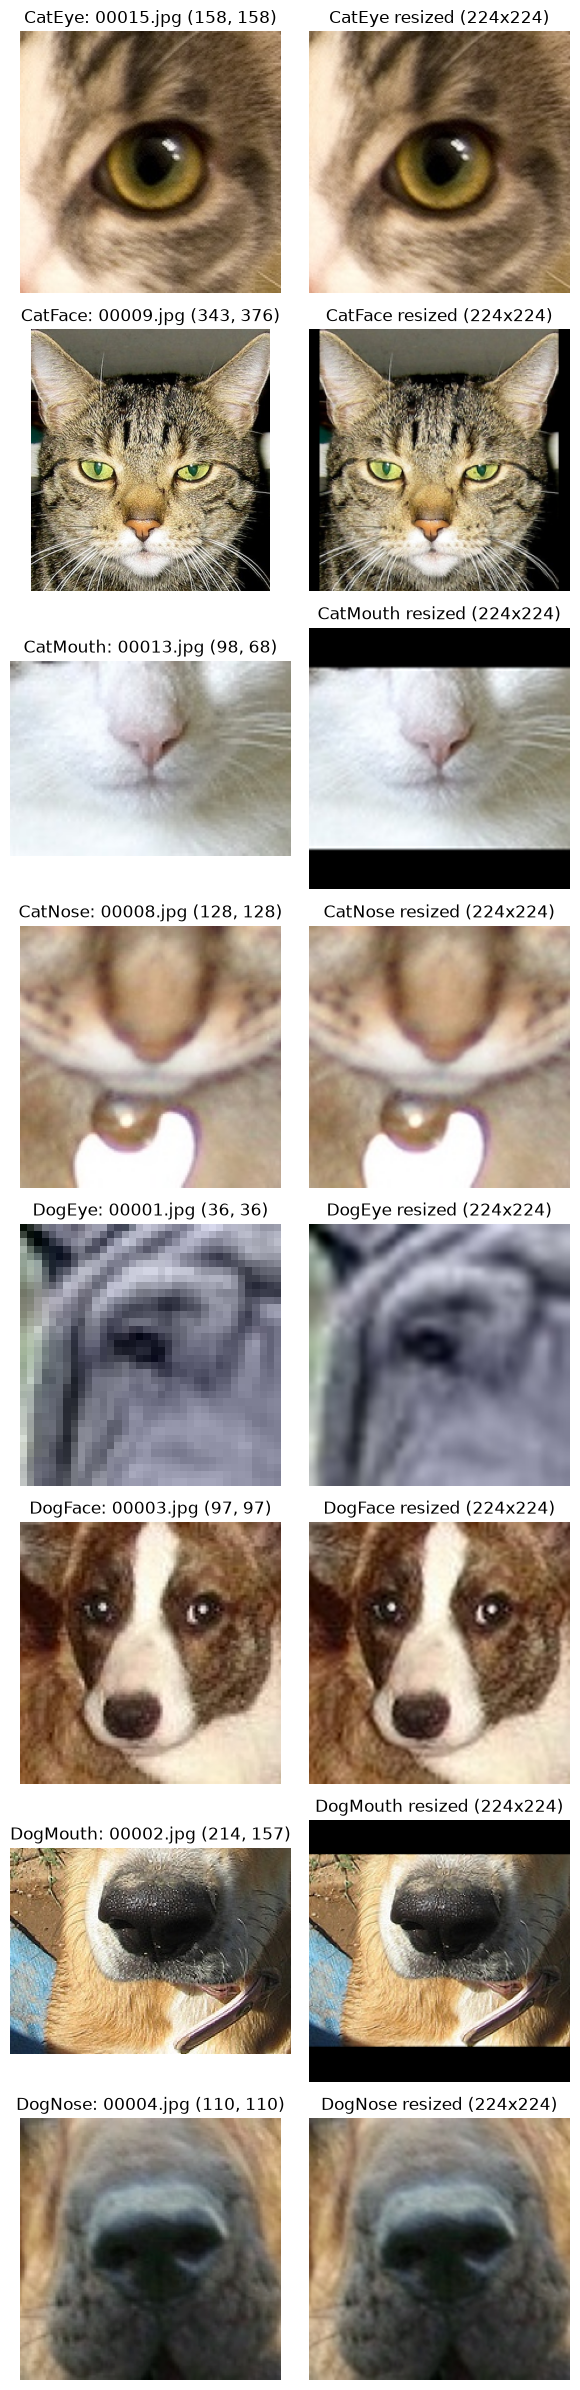

In [43]:
# Resize images to 224x224, the standard input size for ImageNet-pretrained models.
# Images are padded to a square first so the animal features are not stretched.
# The preprocessing lives in data_pipeline.py so DataLoader workers can import it.
from PIL import Image
from data_pipeline import IMAGE_SIZE, resize_image

# Preview one resized training image from each class.
samples_per_class = 1
classes = sorted(source_image_labels["class"].unique())
sample_paths_by_class = {
    class_name: [
        training_image_path(image_id)
        for image_id in source_image_labels.loc[
            source_image_labels["class"] == class_name, "image_id"
        ].head(samples_per_class)
    ]
    for class_name in classes
}
sample_paths = [path for paths in sample_paths_by_class.values() for path in paths]
resized_sizes = Counter()
for path in sample_paths:
    with Image.open(path) as img:
        resized_sizes[resize_image(img).size] += 1
print(
    f"Resized image sizes and counts for {len(sample_paths)} sample images: {dict(resized_sizes)}"
)

# One row per class: the original on the left, the resized version on the right.
fig, axes = plt.subplots(
    len(sample_paths), 2, figsize=(6, 3 * len(sample_paths)), squeeze=False
)
labelled_samples = [
    (class_name, path)
    for class_name, paths in sample_paths_by_class.items()
    for path in paths
]
for row, (class_name, path) in enumerate(labelled_samples):
    with Image.open(path) as img:
        axes[row, 0].imshow(img)
        axes[row, 0].set_title(f"{class_name}: {path.name} {img.size}")
        axes[row, 1].imshow(resize_image(img))
        axes[row, 1].set_title(f"{class_name} resized ({IMAGE_SIZE}x{IMAGE_SIZE})")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

Raw pixels:        min=0.0, max=255.0, mean per channel=[132.4 120.4 107.5]
Normalised pixels: min=0.00, max=1.00, mean per channel=[0.52 0.47 0.42], std per channel=[0.28 0.27 0.27]


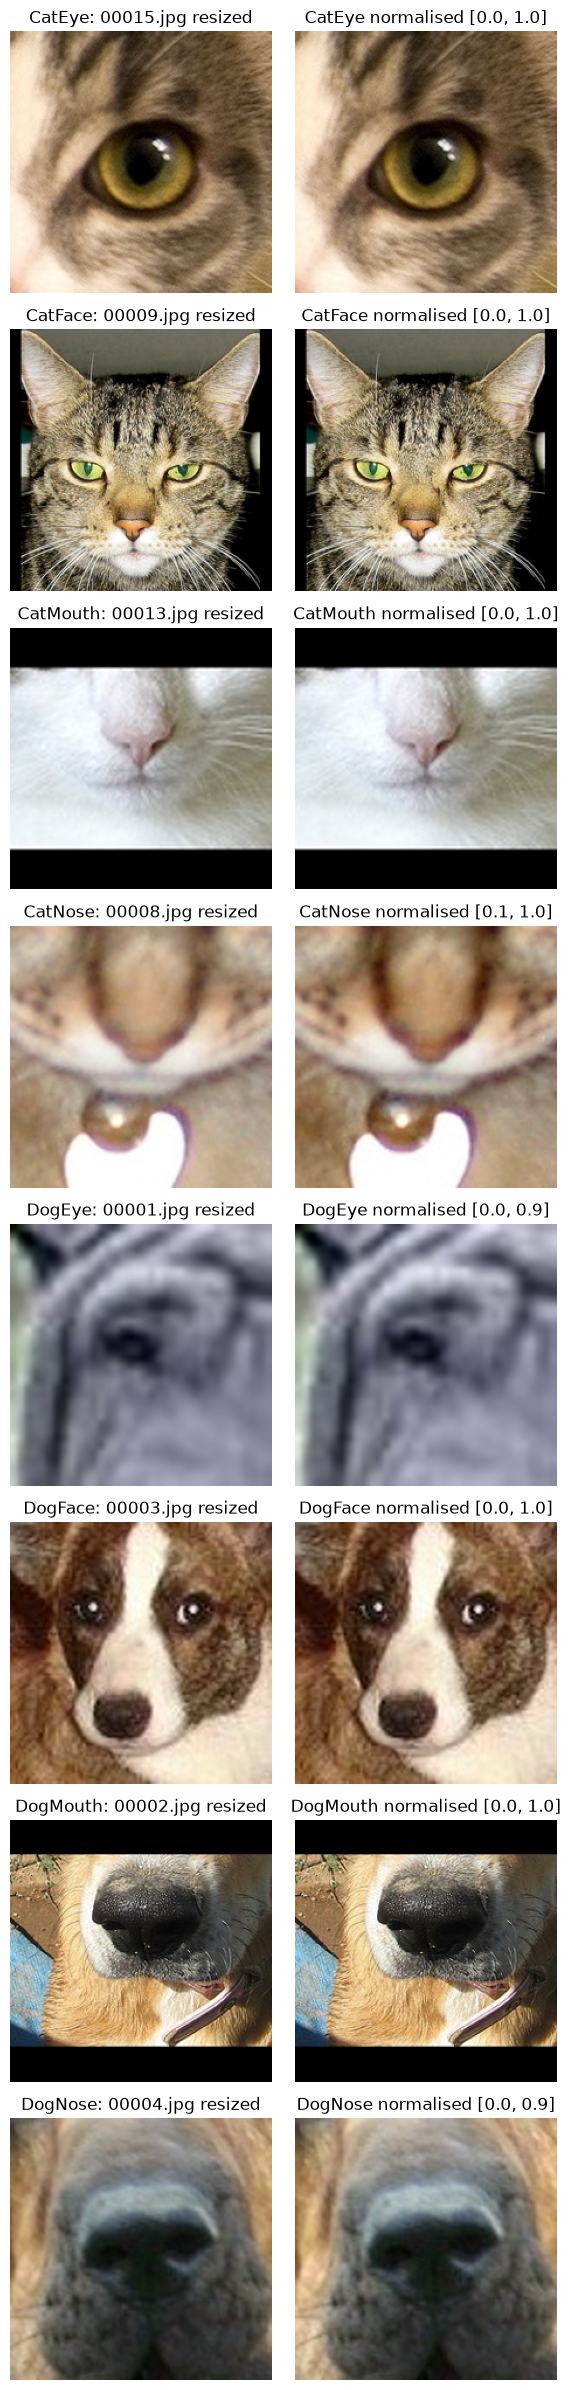

In [44]:
# Rescale pixels to [0, 1], then standardise with the ImageNet mean and std.
# Fixed ImageNet statistics match pretrained models and avoid fitting anything on the data (no leakage).
import numpy as np
from data_pipeline import normalise_image, resize_image

# Preview pixel statistics on one image from each class; the data loader normalizes the full dataset.
samples_per_class = 1
classes = sorted(source_image_labels["class"].unique())
sample_paths_by_class = {
    class_name: [
        training_image_path(image_id)
        for image_id in source_image_labels.loc[
            source_image_labels["class"] == class_name, "image_id"
        ].head(samples_per_class)
    ]
    for class_name in classes
}
sample_paths = [path for paths in sample_paths_by_class.values() for path in paths]
raw_pixels, normalised_pixels = [], []
for path in sample_paths:
    with Image.open(path) as img:
        raw_pixels.append(
            np.asarray(resize_image(img), dtype=np.float32).reshape(-1, 3)
        )
        normalised_pixels.append(normalise_image(img).reshape(-1, 3))
raw_pixels = np.concatenate(raw_pixels)
normalised_pixels = np.concatenate(normalised_pixels)

print(
    f"Raw pixels:        min={raw_pixels.min():.1f}, max={raw_pixels.max():.1f}, "
    f"mean per channel={raw_pixels.mean(axis=0).round(1)}"
)
print(
    f"Normalised pixels: min={normalised_pixels.min():.2f}, max={normalised_pixels.max():.2f}, "
    f"mean per channel={normalised_pixels.mean(axis=0).round(2)}, "
    f"std per channel={normalised_pixels.std(axis=0).round(2)}"
)

# Normalised values fall outside [0, 1], so min-max scale them for display only.
# One row per class: the resized image on the left, the normalised version on the right.
fig, axes = plt.subplots(
    len(sample_paths), 2, figsize=(6, 3 * len(sample_paths)), squeeze=False
)
labelled_samples = [
    (class_name, path)
    for class_name, paths in sample_paths_by_class.items()
    for path in paths
]
for row, (class_name, path) in enumerate(labelled_samples):
    with Image.open(path) as img:
        normalised = normalise_image(img)
        axes[row, 0].imshow(resize_image(img))
        axes[row, 0].set_title(f"{class_name}: {path.name} resized")
        displayed = (normalised - normalised.min()) / (
            normalised.max() - normalised.min()
        )
        axes[row, 1].imshow(displayed)
        axes[row, 1].set_title(
            f"{class_name} normalised [{normalised.min():.1f}, {normalised.max():.1f}]"
        )
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [45]:
# Encode class names as integer labels (0-7), as expected by PyTorch cross-entropy loss.
# The mapping comes from the sorted class names, so it is stable between runs.
class_names = sorted(source_image_labels["class"].unique())
class_to_idx = {name: index for index, name in enumerate(class_names)}
idx_to_class = {index: name for name, index in class_to_idx.items()}
NUM_CLASSES = len(class_names)

train_labels = train_labels.assign(label=train_labels["class"].map(class_to_idx))
validation_labels = validation_labels.assign(
    label=validation_labels["class"].map(class_to_idx)
)

print(f"Number of classes: {NUM_CLASSES}")
print("Class to index mapping:")
for name, index in class_to_idx.items():
    print(f"  {index}: {name}")

assert train_labels["label"].notna().all() and validation_labels["label"].notna().all()
assert all(idx_to_class[index] == name for name, index in class_to_idx.items())
print("\nTraining labels with encoded values:")
print(train_labels.head().to_string(index=False))

Number of classes: 8
Class to index mapping:
  0: CatEye
  1: CatFace
  2: CatMouth
  3: CatNose
  4: DogEye
  5: DogFace
  6: DogMouth
  7: DogNose

Training labels with encoded values:
 image_id    class  label
    26977  CatNose      3
    43790 DogMouth      6
    60045   CatEye      0
    47430   DogEye      4
    50148 DogMouth      6


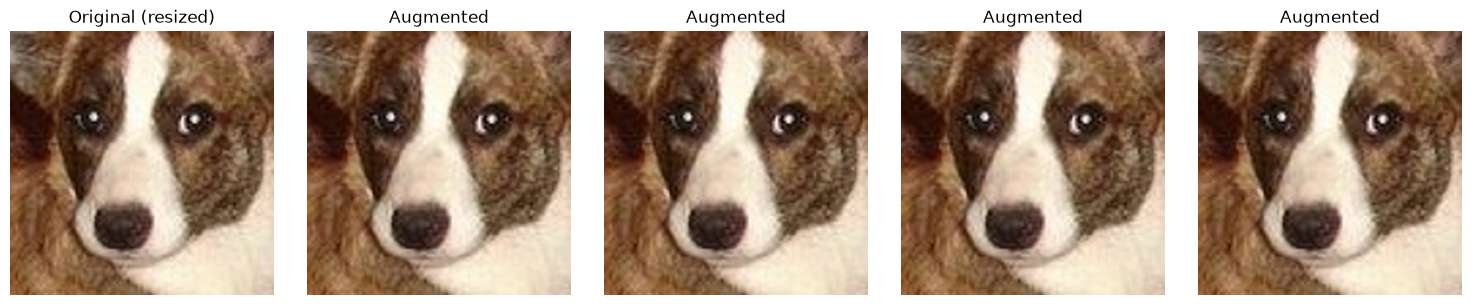

In [46]:
# Light data augmentation for the training set only (validation and test are never augmented).
# Horizontal flip, small rotation and mild brightness/contrast changes keep the class label valid.
# Vertical flips, heavy crops and strong colour shifts are avoided.
import random
from data_pipeline import augment_image, resize_image

# Show one training image and several random augmented versions of it.
rng = random.Random(42)
sample_path = training_image_path(source_image_labels["image_id"].iloc[2])
with Image.open(sample_path) as img:
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))
    axes[0].imshow(resize_image(img))
    axes[0].set_title("Original (resized)")
    for ax in axes[1:]:
        ax.imshow(augment_image(img, rng))
        ax.set_title("Augmented")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [47]:
# Dataset and DataLoaders: images are loaded from disk one batch at a time,
# and augmentation is applied on the fly (training only).
import os
import torch
from torch.utils.data import DataLoader
from data_pipeline import CatDogDataset

BATCH_SIZE = 16
SEED = 42
torch.manual_seed(SEED)

train_dataset = CatDogDataset(
    train_dir, train_labels["image_id"], train_labels["label"], augment=True
)
val_dataset = CatDogDataset(
    train_dir, validation_labels["image_id"], validation_labels["label"]
)

# The test set has no labels, so only images are returned.
test_ids = sorted(int(path.stem) for path in test_dir.glob("*.jpg"))
test_dataset = CatDogDataset(test_dir, test_ids)

# Leave one CPU for the main process. Capped at 8 because each loader keeps its own
# persistent workers, and each spawned worker re-imports torch on Windows.
# Workers are safe in Jupyter because CatDogDataset is imported from data_pipeline.py.
NUM_WORKERS = min(8, max(1, (os.cpu_count() or 1) - 1))
print(f"DataLoader workers: {NUM_WORKERS} (of {os.cpu_count()} CPUs)")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    persistent_workers=NUM_WORKERS > 0,
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    persistent_workers=NUM_WORKERS > 0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    persistent_workers=NUM_WORKERS > 0,
)

for name, dataset, loader in [
    ("Train", train_dataset, train_loader),
    ("Validation", val_dataset, val_loader),
    ("Test", test_dataset, test_loader),
]:
    print(f"{name}: {len(dataset)} images, {len(loader)} batches of up to {BATCH_SIZE}")

images, labels_batch = next(iter(train_loader))
print(f"\nTrain batch images: shape={tuple(images.shape)}, dtype={images.dtype}")
print(f"Train batch labels: {labels_batch.tolist()}")
print(f"Test batch images: shape={tuple(next(iter(test_loader)).shape)}")

DataLoader workers: 8 (of 20 CPUs)
Train: 50916 images, 3183 batches of up to 16
Validation: 12729 images, 796 batches of up to 16
Test: 29443 images, 1841 batches of up to 16

Train batch images: shape=(16, 3, 224, 224), dtype=torch.float32
Train batch labels: [1, 0, 2, 0, 2, 3, 0, 3, 5, 5, 3, 7, 0, 0, 0, 1]
Test batch images: shape=(16, 3, 224, 224)


### Task 3: Model Selection and Pipeline Development

In [48]:
# Select hardware accelerator

import torch

cuda_available = torch.cuda.is_available()

DEVICE = torch.device("cuda") if cuda_available else torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"NVIDIA CUDA: {'available' if cuda_available else 'not available'}")

if DEVICE.type == "cuda":
    print(f"\nSelected device: NVIDIA GPU — {torch.cuda.get_device_name(0)}")
else:
    print("\nSelected device: CPU — training will run without a hardware accelerator.")
    if torch.version.cuda is None:
        print("This PyTorch installation was built without CUDA support.")

PyTorch version: 2.14.1+cu126
NVIDIA CUDA: available

Selected device: NVIDIA GPU — NVIDIA RTX 2000 Ada Generation Laptop GPU


In [49]:
# Shared training utilities used by both the transfer-learning and custom CNN sections.
# The functions are used to train the selected model using the prepared training data.

import copy
import torch.nn as nn
from torchvision import models


def compute_class_weights(labels, class_to_idx):
    """Class imbalance fix: weight each class inversely to its training frequency,
    so errors on rare classes cost more. Pass training-split labels only.
    weight_c = total_samples / (num_classes * count_c)"""
    counts = np.bincount(labels, minlength=len(class_to_idx))
    weights = torch.tensor(
        counts.sum() / (len(counts) * np.maximum(counts, 1)),
        dtype=torch.float32,
    ).to(DEVICE)
    print(
        "Class weights:",
        dict(zip(class_to_idx, weights.cpu().numpy().round(3).tolist())),
    )
    return weights


def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over loader: trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(DEVICE)
            y = torch.as_tensor(y, dtype=torch.long, device=DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def train_model(model, optimizer, scheduler, criterion, epochs, patience, save_path):
    """Train with early stopping, restore and save the best weights, return (history, best_val_loss)."""
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss, best_state, wait = float("inf"), None, 0
    for epoch in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        scheduler.step()
        for key, value in zip(history, (tl, ta, vl, va)):
            history[key].append(value)
        print(
            # Monitor training and validation accuracy and loss.
            f"Epoch {epoch:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}"
        )
        if vl < best_val_loss:
            best_val_loss, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping")
                break
    model.load_state_dict(best_state)
    torch.save(best_state, save_path)
    print(f"Best validation loss: {best_val_loss:.3f}")
    return history, best_val_loss

In [50]:
# Shared plotting, evaluation and prediction utilities used by both models.
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)


def plot_learning_curves(history, name):
    """Training vs validation loss and accuracy per epoch."""
    epochs_run = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_run, history["train_loss"], label="Train")
    axes[0].plot(epochs_run, history["val_loss"], label="Validation")
    axes[0].set(title=f"{name}: loss", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].plot(epochs_run, history["train_acc"], label="Train")
    axes[1].plot(epochs_run, history["val_acc"], label="Validation")
    axes[1].set(
        title=f"{name}: accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05)
    )
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def evaluate_model(model, name):
    """Validation report, confusion matrix (counts), class accuracy and precision/recall/F1 plots."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in val_loader:
            y_pred.extend(model(x.to(DEVICE)).argmax(1).cpu().tolist())
            y_true.extend(torch.as_tensor(y).tolist())

    val_loss_final, val_acc_final = run_epoch(model, val_loader, criterion)
    print(
        f"{name} | validation loss: {val_loss_final:.3f} | accuracy: {val_acc_final:.1%}"
    )

    label_ids = list(range(NUM_CLASSES))
    print(
        classification_report(
            y_true, y_pred, labels=label_ids, target_names=class_names, zero_division=0
        )
    )

    cm = confusion_matrix(y_true, y_pred, labels=label_ids)
    # Class-level accuracy = recall = diagonal / images of that class (NaN if class absent).
    support = cm.sum(axis=1)
    class_acc = np.divide(
        cm.diagonal(), support, out=np.full(NUM_CLASSES, np.nan), where=support > 0
    )
    print("Class-level accuracy:")
    for cname, acc, n_images in zip(class_names, class_acc, support):
        print(f"  {cname:10s} {acc:.1%} ({n_images} validation images)")

    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
    )
    ax.set_title(f"{name}: confusion matrix (counts)")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 3.5))
    plt.bar(class_names, np.nan_to_num(class_acc))
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45)
    plt.ylabel("Accuracy")
    plt.title(f"{name}: class-level validation accuracy")
    plt.tight_layout()
    plt.show()

    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=label_ids, zero_division=0
    )
    positions = np.arange(NUM_CLASSES)
    width = 0.27
    plt.figure(figsize=(11, 4.5))
    plt.bar(positions - width, prec, width, label="Precision")
    plt.bar(positions, rec, width, label="Recall")
    plt.bar(positions + width, f1, width, label="F1-score")
    plt.xticks(positions, class_names, rotation=45)
    plt.ylim(0, 1.05)
    plt.ylabel("Score")
    plt.title(f"{name}: per-class precision, recall and F1-score (validation)")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [51]:
# Shared prediction and submission utilities for Kaggle competition.


def predict_and_save(model, output_name):
    """Predict the Kaggle test set and write output_name to submission_dir."""
    model.eval()
    pred_idx = []
    with torch.no_grad():
        for x in test_loader:
            probs = torch.softmax(model(x.to(DEVICE)), dim=1)
            pred_idx.extend(probs.argmax(1).cpu().tolist())

    submission = pd.DataFrame(
        {"image_id": test_ids, "class": [idx_to_class[i] for i in pred_idx]}
    )
    assert len(submission) == len(test_dataset)
    submission.to_csv(submission_dir / output_name, index=False)
    print(submission.head())
    return submission

In [52]:
# Custom CNN trained from scratch.

# Model specification:
#   Input image size: 3 x 224 x 224 (RGB)
#   Architecture: Three convolution blocks with 32, 64, then 128 channels; each uses
#     batch normalization, ReLU, and max pooling, followed by adaptive average pooling
#   Output layer: Dropout (0.4) + linear layer producing logits (no softmax)
#   Activation function: ReLU after each convolution block
#   Target classes: NUM_CLASSES (8)
# Training configuration:
#   Loss function: Cross-entropy for mutually exclusive classes; it consumes logits directly
#   Optimizer: AdamW with weight decay (1e-3) for adaptive updates and regularization
#   Learning rate: 3e-4, a moderate starting rate for training this CNN from scratch
#   Batch size: 16, balancing memory use and gradient stability
#   Epochs: Up to 60, with early stopping after 7 unimproved validation epochs
#   Learning-rate schedule: Cosine annealing gradually reduces the learning rate

import copy
import torch.nn as nn

EPOCHS, PATIENCE = 60, 7


def build_custom_cnn(num_classes=NUM_CLASSES):
    return nn.Sequential(
        # Input: 3 x 224 x 224
        nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(128),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d((1, 1)),
        nn.Flatten(),
        nn.Dropout(0.4),
        nn.Linear(128, num_classes),
    )


torch.manual_seed(SEED)
custom_cnn_model = build_custom_cnn().to(DEVICE)
print(custom_cnn_model)
print(
    f"Trainable parameters: {sum(p.numel() for p in custom_cnn_model.parameters()):,}"
)

# Weight the loss by class frequency in the training split (see compute_class_weights).
class_weights = compute_class_weights(train_labels["label"], class_to_idx)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(custom_cnn_model.parameters(), lr=3e-4, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

custom_history, best_val_loss = train_model(
    custom_cnn_model,
    optimizer,
    scheduler,
    criterion,
    EPOCHS,
    PATIENCE,
    models_dir / f"train_{source_image_labels_count}_best_custom_cnn.pt",
)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU(inplace=True)
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): AdaptiveAvgPool2d(output_size=(1, 1))
  (13): Flatten(start_dim=1, end_dim=-1)
  (14): Dropout(p=0.4, in

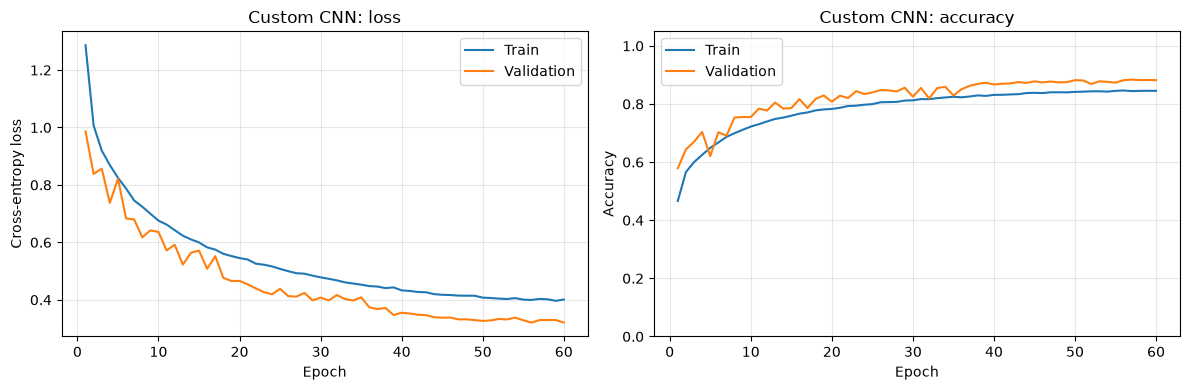

In [53]:
# Plot learning curves for the custom CNN model.
plot_learning_curves(custom_history, "Custom CNN")

Custom CNN | validation loss: 0.321 | accuracy: 88.2%
              precision    recall  f1-score   support

      CatEye       0.93      0.85      0.89      2775
     CatFace       0.97      0.96      0.97      1389
    CatMouth       0.98      0.99      0.98      1388
     CatNose       0.85      0.89      0.87      1388
      DogEye       0.79      0.80      0.80      2315
     DogFace       0.85      0.87      0.86      1158
    DogMouth       0.98      0.99      0.99      1158
     DogNose       0.72      0.79      0.75      1158

    accuracy                           0.88     12729
   macro avg       0.88      0.89      0.89     12729
weighted avg       0.88      0.88      0.88     12729

Class-level accuracy:
  CatEye     85.0% (2775 validation images)
  CatFace    96.5% (1389 validation images)
  CatMouth   98.9% (1388 validation images)
  CatNose    89.0% (1388 validation images)
  DogEye     80.0% (2315 validation images)
  DogFace    86.6% (1158 validation images)
  DogMout

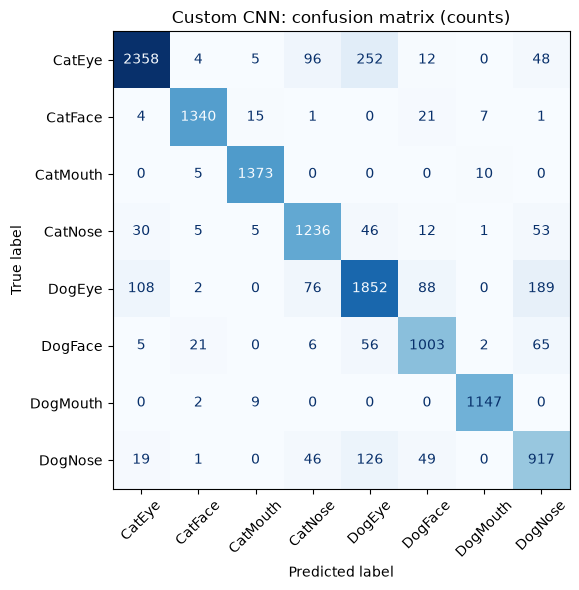

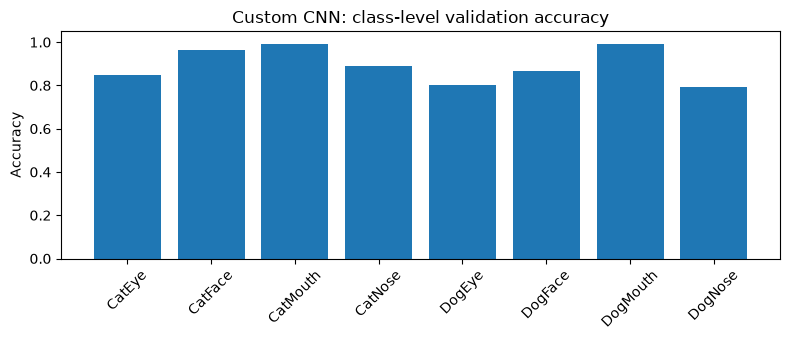

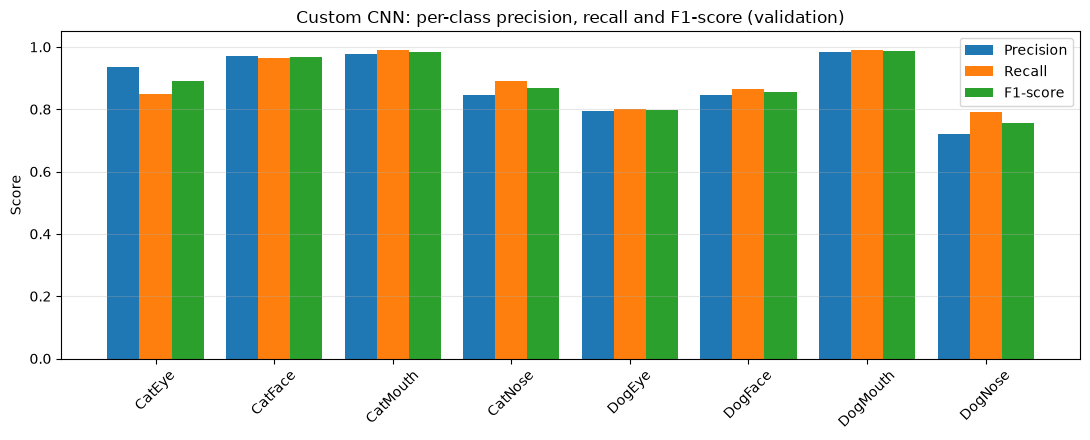

In [54]:
# Validation metrics and plots for the custom CNN model.
evaluate_model(custom_cnn_model, "Custom CNN")

In [55]:
# Transfer learning model: ImageNet-pretrained ResNet-18 with a new 8-class head.

# Model specification:
#   Input image size: 3 x 224 x 224 (RGB)
#   Architecture: ImageNet-pretrained ResNet-18 with residual skip connections
#   Activation function: ReLU in the backbone
#   Output layer: Dropout (0.3) + linear layer producing logits (no softmax)
#   Target classes: NUM_CLASSES (8)

# Training configuration:
#   Loss function: Cross-entropy with label smoothing (0.1), for mutually exclusive classes
#     and to discourage overconfident predictions
#   Optimizer: AdamW with weight decay, for adaptive updates and regularization
#   Learning rates: 1e-4 for the pretrained backbone (preserve learned features);
#     1e-3 for the new head (learn task-specific classes faster)
#   Batch size: 16, balancing memory use and gradient stability
#   Epochs: Up to 20, with early stopping after 5 unimproved validation epochs
#   Learning-rate schedule: Cosine annealing gradually reduces both learning rates

EPOCHS, PATIENCE = 20, 5


def build_resnet18(num_classes=NUM_CLASSES, pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    # Replace the 1000-class ImageNet layer with dropout + a linear layer for our classes.
    model.fc = nn.Sequential(
        nn.Dropout(0.3), nn.Linear(model.fc.in_features, num_classes)
    )
    return model


torch.manual_seed(SEED)
transfer_model = build_resnet18().to(DEVICE)
trainable = sum(p.numel() for p in transfer_model.parameters() if p.requires_grad)
print(f"Device: {DEVICE} | trainable parameters: {trainable:,}")
print(transfer_model.fc)

# Weight the loss by class frequency in the training split (see compute_class_weights).
class_weights = compute_class_weights(train_labels["label"], class_to_idx)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
head_params = list(transfer_model.fc.parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in transfer_model.parameters() if id(p) not in head_ids]
optimizer = torch.optim.AdamW(
    [{"params": backbone_params, "lr": 1e-4}, {"params": head_params, "lr": 1e-3}],
    weight_decay=1e-2,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

transfer_history, best_val_loss = train_model(
    transfer_model,
    optimizer,
    scheduler,
    criterion,
    EPOCHS,
    PATIENCE,
    models_dir / f"train_{source_image_labels_count}_best_resnet18.pt",
)

Device: cuda | trainable parameters: 11,180,616
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=512, out_features=8, bias=True)
)
Class weights: {'CatEye': 0.5730000138282776, 'CatFace': 1.1460000276565552, 'CatMouth': 1.1460000276565552, 'CatNose': 1.1460000276565552, 'DogEye': 0.6869999766349792, 'DogFace': 1.375, 'DogMouth': 1.3739999532699585, 'DogNose': 1.3739999532699585}
Epoch 01 | train loss 0.592 acc 0.976 | val loss 0.551 acc 0.993
Epoch 02 | train loss 0.541 acc 0.992 | val loss 0.522 acc 0.994
Epoch 03 | train loss 0.529 acc 0.995 | val loss 0.537 acc 0.992
Epoch 04 | train loss 0.523 acc 0.996 | val loss 0.522 acc 0.994
Epoch 05 | train loss 0.520 acc 0.997 | val loss 0.526 acc 0.994
Epoch 06 | train loss 0.517 acc 0.998 | val loss 0.517 acc 0.996
Epoch 07 | train loss 0.515 acc 0.999 | val loss 0.522 acc 0.994
Epoch 08 | train loss 0.513 acc 0.999 | val loss 0.516 acc 0.995
Epoch 09 | train loss 0.510 acc 1.000 | val loss 0.515 acc 0.996
Epoch 1

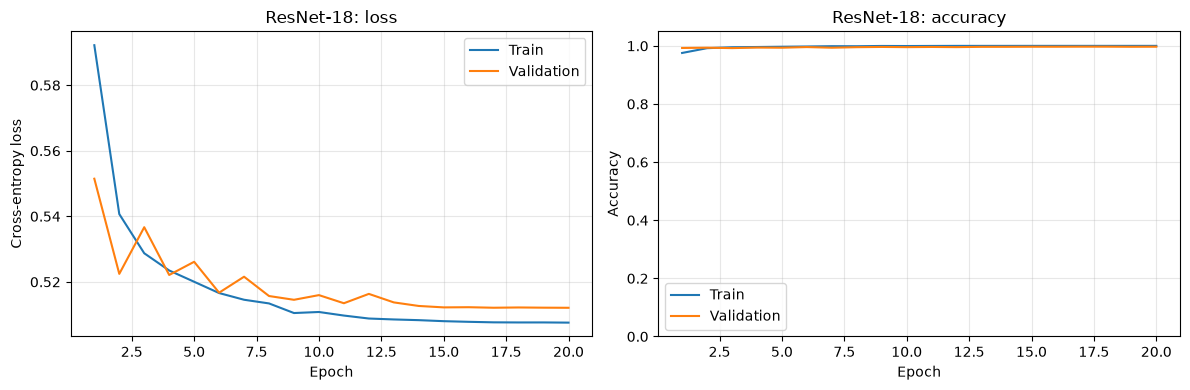

In [56]:
# Plot learning curves for the ResNet-18 model.
plot_learning_curves(transfer_history, "ResNet-18")

ResNet-18 | validation loss: 0.512 | accuracy: 99.7%
              precision    recall  f1-score   support

      CatEye       1.00      1.00      1.00      2775
     CatFace       1.00      1.00      1.00      1389
    CatMouth       1.00      1.00      1.00      1388
     CatNose       1.00      0.99      0.99      1388
      DogEye       0.99      1.00      1.00      2315
     DogFace       1.00      1.00      1.00      1158
    DogMouth       1.00      1.00      1.00      1158
     DogNose       0.99      1.00      1.00      1158

    accuracy                           1.00     12729
   macro avg       1.00      1.00      1.00     12729
weighted avg       1.00      1.00      1.00     12729

Class-level accuracy:
  CatEye     99.7% (2775 validation images)
  CatFace    100.0% (1389 validation images)
  CatMouth   100.0% (1388 validation images)
  CatNose    98.7% (1388 validation images)
  DogEye     99.7% (2315 validation images)
  DogFace    99.9% (1158 validation images)
  DogMou

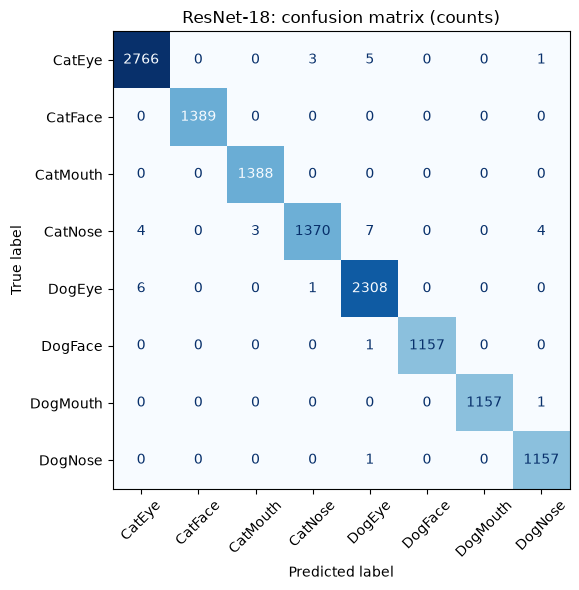

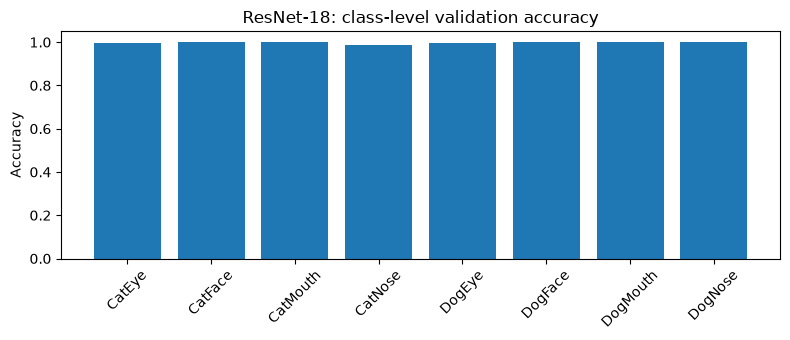

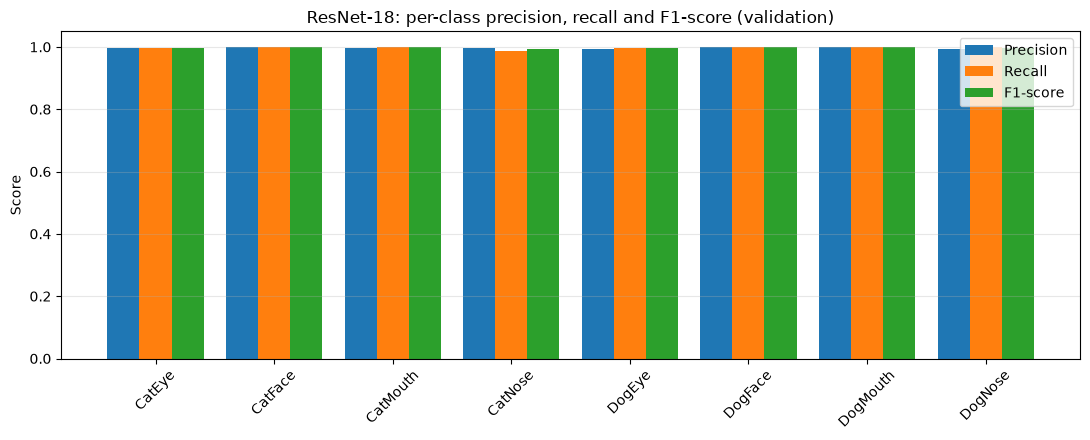

In [57]:
# Validation metrics and plots for the ResNet-18 model.
evaluate_model(transfer_model, "ResNet-18")

#### Identify signs of overfitting or underfitting
Compare the training and validation curves across epochs—don’t judge from a single epoch. The notebook’s training loop records both losses and accuracies, and its learning-curve plots show them side by side (training loop, plot function).

**Overfitting:**
Training loss keeps falling and training accuracy gets high, while validation loss stops improving or rises and validation accuracy stalls or falls. The widening gap is the warning sign.

**Underfitting:**
Both training and validation performance remain poor—for example, both losses stay high and both accuracies stay low.

**Good fit:**
Both losses improve, both accuracies rise, and the gap between training and validation stays reasonably small.

In the recorded ResNet-18 run, training accuracy reached 1.0 while validation accuracy plateaued at 0.812; validation loss reached its best value at 0.940, then rose. That suggests overfitting after the best-validation-loss epoch. For the Custom CNN run, both accuracies were relatively low, which may indicate underfitting, though its learning curves and additional training context matter.

The notebook uses early stopping based on validation loss, which helps stop training when that metric no longer improves.

#### Apply appropriate strategies to improve generalisation

**Data augmentation:**
Training images get random horizontal flips, small rotations, and mild brightness/contrast changes; validation and test images are not augmented (augmentation function, dataset setup).

**Dropout:**
Dropout is a regularisation technique that reduces overfitting. During training, it randomly sets a fraction of a layer's outputs to zero on each forward pass. At evaluation time, it is switched off.

In the notebook, both models use dropout in the classifier head, just before the final linear layer. The custom CNN has nn.Dropout(0.4) before nn.Linear(128, num_classes), and ResNet-18's replacement head is dropout plus linear. 

**Class weighting:**
Class weighting makes mistakes on under-represented classes cost more, so the model cannot get a low loss by favouring the common classes. Each weight is total samples / (number of classes × class count), computed from the training split only.

In the notebook, compute_class_weights is called before training each model, and its result is passed to nn.CrossEntropyLoss(weight=...), combined with label smoothing for ResNet-18. The training split is currently balanced, so every weight is 1.0 and the loss is unchanged; the weights only take effect if the class distribution becomes imbalanced, for example with the full dataset.

**Weight decay:** 
Weight decay is a form of regularization that discourages the model’s weights from growing too large. This can make the model less prone to memorizing training examples and may improve performance on unseen data. 

The notebook applies it through the weight_decay parameter in the AdamW optimizer: 1e-3 for the custom CNN and 1e-2 for ResNet-18.

**Batch normalization:**
Batch normalization normalizes the activations inside a neural network using statistics from each mini-batch, then learns adjustments to those values. It often makes training more stable and can help it converge faster. 

In the notebook, nn.BatchNorm2d appears after each convolution in the custom CNN. The ResNet-18 backbone also includes batch-normalization layers as part of its architecture.

**Early stopping:**
Early stopping stops training when validation performance stops improving, rather than continuing for all planned epochs. This can help avoid overfitting and save training time.

In the notebook, it monitors validation loss. If it fails to improve for 6 consecutive epochs (PATIENCE = 6), training stops. The model then restores and saves the weights from the epoch with the best validation loss (training loop).

**Learning-rate scheduling:**
Learning-rate scheduling gradually changes the learning rate during training-the rate at which the model updates its weights. 

In the notebook, cosine annealing lowers it over the planned epochs: larger updates early, smaller ones later. This can help the model converge more smoothly.

**Transfer learning:**
Transfer learning means starting with a model already trained on a large dataset and adapting it to a new task. The pretrained model has already learned useful visual features, such as edges, shapes, and textures, so it can be more effective when the labeled dataset is small.

In the notebook, ResNet-18 starts with ImageNet-pretrained weights and replaces its original output layer with a new classifier for the eight classes. The optimizer updates both the pretrained backbone and the new classifier head, with a lower learning rate for the backbone.

**Fine-tuning:**
Fine-tuning is a form of transfer learning: start with a pretrained model, then continue training some or all of its learned layers on the dataset so its features adapt to the task.

The notebook fine-tunes ResNet-18: it replaces the original ImageNet classifier with an eight-class head and trains both that head and the pretrained backbone. The backbone uses a lower learning rate (1e-4) than the new head (1e-3), so its existing features change more cautiously.

**Model adjustment:**
Model adjustment means changing a model’s architecture or settings to better suit the task—for example, changing the classifier’s output size, adding dropout, or choosing a simpler or more suitable network.

The notebook does this in two ways: it builds a custom CNN with batch normalization and dropout, and replaces ResNet-18’s original 1,000-class output layer with a dropout-plus-linear head for the 8 classes.

#### Present and discuss learning curves for training and validation performance.
The notebook plots training and validation loss and accuracy across epochs:

Each plot has a loss chart and an accuracy chart, with separate lines for training and validation (plotting function). Compare the lines to see whether the model is learning and whether it may be overfitting.

### Create Kaggle submission from the saved models

In [58]:
# Load each saved model and write its submission file, reusing predict_and_save and the model builders above.
# Per-model settings: how to rebuild it, which weights file to load, which submission to write.
MODEL_CONFIGS = {
    "custom_cnn": {
        "builder": build_custom_cnn,
        "model_file": f"train_{source_image_labels_count}_best_custom_cnn.pt",
        "submission_file": f"train_{source_image_labels_count}_final_submission_best_custom_cnn.csv",
    },
    "resnet18": {
        "builder": lambda: build_resnet18(
            pretrained=False
        ),  # weights come from the saved file
        "model_file": f"train_{source_image_labels_count}_best_resnet18.pt",
        "submission_file": f"train_{source_image_labels_count}_final_submission_best_resnet18.csv",
    },
}

for model_name, config in MODEL_CONFIGS.items():
    loaded_model = config["builder"]().to(DEVICE)
    loaded_model.load_state_dict(
        torch.load(
            models_dir / config["model_file"], map_location=DEVICE, weights_only=True
        )
    )
    predict_and_save(loaded_model, config["submission_file"])
    print(f"{config['model_file']} ({model_name}) -> {config['submission_file']}\n")

   image_id     class
0         1    DogEye
1         2  CatMouth
2         3    DogEye
3         4   DogFace
4         5  CatMouth
train_63660_best_custom_cnn.pt (custom_cnn) -> train_63660_final_submission_best_custom_cnn.csv

   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4   DogFace
4         5  CatMouth
train_63660_best_resnet18.pt (resnet18) -> train_63660_final_submission_best_resnet18.csv

